In [1]:
import pandas as pd
import numpy as np

# Use one shared seed so every group member can reproduce the same split.
RANDOM_STATE = 313

# Load both years and combine them into one DataFrame
df_2023 = pd.read_excel('ttc-subway-delay-data-2023.xlsx')
df_2024 = pd.read_excel('ttc-subway-delay-data-2024.xlsx')
df = pd.concat([df_2023, df_2024], ignore_index=True)

# Inspect dataset size, column names, and data types
print(f"Dataset Size: {df.shape[0]} rows and {df.shape[1]} columns")
display(df.info())
display(df.head())

Dataset Size: 49416 rows and 10 columns
<class 'pandas.DataFrame'>
RangeIndex: 49416 entries, 0 to 49415
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       49416 non-null  datetime64[us]
 1   Time       49416 non-null  str           
 2   Day        49416 non-null  str           
 3   Station    49416 non-null  str           
 4   Code       49416 non-null  str           
 5   Min Delay  49416 non-null  int64         
 6   Min Gap    49416 non-null  int64         
 7   Bound      31370 non-null  str           
 8   Line       49324 non-null  str           
 9   Vehicle    49416 non-null  int64         
dtypes: datetime64[us](1), int64(3), str(6)
memory usage: 3.8 MB


None

,Date,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Line,Vehicle
0,2023-01-01,02:22,Sunday,MUSEUM STATION,MUPAA,3,9,S,YU,5931
1,2023-01-01,02:30,Sunday,KIPLING STATION,MUIS,0,0,E,BD,5341
2,2023-01-01,02:33,Sunday,WARDEN STATION,SUO,0,0,W,BD,0
3,2023-01-01,03:17,Sunday,KEELE STATION,MUIS,0,0,NaN,BD,0
4,2023-01-01,07:16,Sunday,BATHURST STATION,MUIS,0,0,NaN,BD,0


## Feature Categorization

Feature categorization means grouping columns according to the kind of information they contain and how they will be used in the analysis.

| Category | Features | Explanation |
|---|---|---|
| Temporal | `Date`, `Time`, `Day` | Describe when the subway delay occurred. |
| Categorical | `Station`, `Code`, `Bound`, `Line` | Describe groups or labels, such as the station, delay type, direction, and subway line. |
| Numerical | `Min Delay`, `Min Gap` | Contain numerical measurements of delay and service-gap duration in minutes. |
| Identifier-like | `Vehicle` | Identifies a subway vehicle. A value of `0` may indicate that a vehicle was unavailable or not applicable. |
| Target variable | `Min Delay` | The regression target because we want to predict the exact delay duration. |
| Derived target variable | `Prolonged_Disruption` | The classification target, created later as 1 when `Min Delay` is greater than 15 minutes and 0 otherwise. |

### Why categorize the features?

Categorizing features helps us choose the correct EDA and preprocessing methods.

- Numerical features can be summarized using means, medians, standard deviations, and histograms.
- Categorical features can be examined using frequency counts and bar charts.
- Temporal features can be used to investigate patterns by hour, day, weekday, or month.
- Identifier-like features may need special treatment because their numbers are labels, not measurements.
- Target variables must be analyzed separately because they are the outcomes that future machine-learning models will predict.

In [2]:
# Categorize the original features by their role and data type
temporal_features = [
    "Date",
    "Time",
    "Day"
]

categorical_features = [
    "Station",
    "Code",
    "Bound",
    "Line"
]

numeric_features = [
    "Min Delay",
    "Min Gap"
]

identifier_features = [
    "Vehicle"
]

target_variables = [
    "Min Delay",
    "Prolonged_Disruption"
]

feature_categories = {
    "Temporal": temporal_features,
    "Categorical": categorical_features,
    "Numerical": numeric_features,
    "Identifier-like": identifier_features,
    "Target variables": target_variables
}

for category, features in feature_categories.items():
    print(f"{category}: {features}")

Temporal: ['Date', 'Time', 'Day']
Categorical: ['Station', 'Code', 'Bound', 'Line']
Numerical: ['Min Delay', 'Min Gap']
Identifier-like: ['Vehicle']
Target variables: ['Min Delay', 'Prolonged_Disruption']


## Creating the Training and Test Sets

Before building a machine-learning model, we divide the data into two parts:

- **Training set (80%)**: used to teach the model patterns in the data.
- **Test set (20%)**: kept separate until the end and used to evaluate how well the model works on unseen records.

We use stratified sampling for this split. Stratification means that the training and test sets keep similar proportions of important groups from the full dataset. Here, the stratification groups combine:

1. Whether the delay is prolonged (`Min Delay > 15` minutes),
2. The season in which the event occurred, and
3. Whether the event occurred on a weekend.

This helps prevent the test set from accidentally containing too many records from one season or too few prolonged disruptions. The split is random but reproducible because we use `random_state=313`.

For this assignment, a random stratified split is suitable because we are asked to use an 80/20 split. For a later real-world deployment study, we could also test a chronological split, where older records train the model and newer records test it.

In [3]:
from sklearn.model_selection import train_test_split

# Create the classification target from the regression target.
df["Prolonged_Disruption"] = (df["Min Delay"] > 15).astype(int)

# Create temporal features used only to balance the split.
df["Month"] = df["Date"].dt.month
# January, February, and December are assigned to Winter.
df["Season"] = df["Month"].map({
    1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall",
    11: "Fall", 12: "Winter"
})
df["Is_Weekend"] = df["Day"].isin(["Saturday", "Sunday"]).astype(int)

# Combine the important groups into one stratification label.
df["stratify_group"] = (
    df["Prolonged_Disruption"].astype(str)
    + "_" + df["Season"]
    + "_" + df["Is_Weekend"].astype(str)
)

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["stratify_group"]
)

# The helper column is no longer needed after the split.
train_df = train_df.drop(columns="stratify_group")
test_df = test_df.drop(columns="stratify_group")

print(f"Training set: {train_df.shape[0]:,} rows")
print(f"Test set: {test_df.shape[0]:,} rows")


Training set: 39,532 rows
Test set: 9,884 rows


The original combined dataset remains in `df`, while `train_df` and `test_df` contain the two subsets. The `Month`, `Season`, `Is_Weekend`, and `Prolonged_Disruption` columns are retained because they will be useful in later EDA and modeling discussions. The original `Min Delay` column should not be used as an input feature when predicting `Prolonged_Disruption`, because the classification target was calculated directly from it.

## Missing-Value and Data-Quality Assessment

A missing value means that no value was recorded for a field. Missingness is not automatically an error: for example, a delay may not have a recorded direction if the direction was unavailable or not applicable. We therefore measure missing values before deciding whether to remove, impute, or keep them.

We perform this assessment before imputation. Imputation means replacing missing values with estimated values, such as a median for a numerical column or the most common category for a categorical column. Those replacements should eventually be learned from the training set only, so information from the test set does not influence the model.

The initial audit showed that approximately 36.52% of `Bound` values are missing, while only about 0.19% of `Line` values are missing. The remaining original columns have no missing values. We will investigate the meaning of missing `Bound` values before selecting a treatment.

In [4]:
# Count and calculate the percentage of missing values in each column.
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})
missing_summary = missing_summary.sort_values(
    by="Missing Percentage", ascending=False
)
display(missing_summary)

# Check the observed date range and whether any dates fall outside the project scope.
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Dates outside 2023-2024: {((df['Date'] < '2023-01-01') | (df['Date'] > '2024-12-31')).sum()}")

# Check for exact duplicate rows and negative numeric values.
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print("Negative numeric values:")
display((df[["Min Delay", "Min Gap", "Vehicle"]] < 0).sum())

,Missing Count,Missing Percentage
Bound,18046,36.52
Line,92,0.19
Date,0,0.00
Station,0,0.00
Code,0,0.00
Time,0,0.00
Day,0,0.00
Min Gap,0,0.00
Min Delay,0,0.00
Vehicle,0,0.00


Date range: 2023-01-01 to 2024-12-31
Dates outside 2023-2024: 0
Exact duplicate rows: 23
Negative numeric values:


Min Delay    0
Min Gap      0
Vehicle      0
dtype: int64

### Initial data-quality decisions

- No date correction is needed because all records are within the selected 2023–2024 range.
- No negative values were found in `Min Delay`, `Min Gap`, or `Vehicle`.
- The 23 exact duplicate rows should be reviewed and removed only if they represent duplicate reports rather than legitimate repeated events.
- Missing `Line` values are rare and can be investigated separately.
- Missing `Bound` values are common. We should not fill them with a guessed direction. For now, we will preserve them and decide later whether to label them as `Unknown` or exclude the column from a particular model.

## Investigating Missing Direction Values

The `Bound` column contains 18,046 missing values, representing approximately 36.52% of the dataset. Instead of immediately imputing these values, we compare records with a recorded direction against records with a missing direction.

This helps determine whether the missingness is random or associated with specific delay codes, subway lines, delay durations, or types of operational events.

Because direction may not be applicable to every incident, replacing missing values with a guessed direction could introduce incorrect information. We will therefore examine the missingness pattern before selecting a final preprocessing strategy.

In [5]:
# Create a flag identifying whether Bound is missing.
df["Bound_Missing"] = df["Bound"].isna()

# Compare the number of records with recorded and missing directions.
bound_missing_counts = (
    df["Bound_Missing"]
    .value_counts()
    .rename({False: "Bound recorded", True: "Bound missing"})
)

display(bound_missing_counts)

# Compare delay statistics for the two groups.
bound_delay_summary = (
    df.groupby("Bound_Missing")["Min Delay"]
    .agg(["count", "mean", "median", "max"])
    .rename(index={False: "Bound recorded", True: "Bound missing"})
    .round(2)
)

display(bound_delay_summary)

# Compare the percentage of prolonged disruptions.
bound_prolonged_rate = (
    df.groupby("Bound_Missing")["Prolonged_Disruption"]
    .mean()
    .mul(100)
    .round(2)
    .rename(index={False: "Bound recorded", True: "Bound missing"})
    .to_frame("Prolonged disruption percentage")
)

display(bound_prolonged_rate)

Bound_Missing
Bound recorded    31370
Bound missing     18046
Name: count, dtype: int64

,count,mean,median,max
Bound_Missing,,,,
Bound recorded,31370,4.48,3.0,716
Bound missing,18046,0.10,0.0,56


,Prolonged disruption percentage
Bound_Missing,
Bound recorded,4.97
Bound missing,0.13


In [6]:
# Identify delay codes with the highest missing-Bound rates.
code_bound_summary = (
    df.groupby("Code")
    .agg(
        Records=("Code", "size"),
        Missing_Bound_Rate=("Bound_Missing", "mean"),
        Average_Delay=("Min Delay", "mean")
    )
)

# Avoid interpreting rates from codes with very few records.
code_bound_summary = (
    code_bound_summary[code_bound_summary["Records"] >= 50]
    .sort_values("Missing_Bound_Rate", ascending=False)
)

code_bound_summary["Missing_Bound_Rate"] = (
    code_bound_summary["Missing_Bound_Rate"] * 100
).round(2)

display(code_bound_summary.head(15))

,Records,Missing_Bound_Rate,Average_Delay
Code,,,
MUNCA,1226,98.53,0.000000
TUNCA,168,95.83,0.000000
PUMEL,1519,93.09,0.023041
MUGD,63,92.06,0.000000
PUMST,597,87.44,0.006700
PUMO,238,84.87,0.306723
MRO,249,79.92,0.674699
MUIS,5393,78.55,0.072687
MUIE,308,77.92,0.301948


## Visualizing the Missing-Bound Pattern

Tables show the exact values, while graphs make differences between groups easier to see. The first chart displays the percentage of missing `Bound` values for the 15 delay codes with the highest rates, using only codes with at least 50 records. The second chart compares the percentage of prolonged disruptions when `Bound` is recorded versus missing.

If missingness were unrelated to the type of event, the delay-code bars would be relatively similar and the two prolonged-disruption rates would be close. Large differences indicate that missing `Bound` values are associated with particular incident patterns. This does not prove the cause of missingness, but it is evidence that the missingness is not uniformly distributed across the dataset.

The graphs support keeping missing directions as missing during EDA rather than replacing them with a guessed compass direction. A later modeling pipeline can represent them as `Unknown` if a complete categorical feature is required.

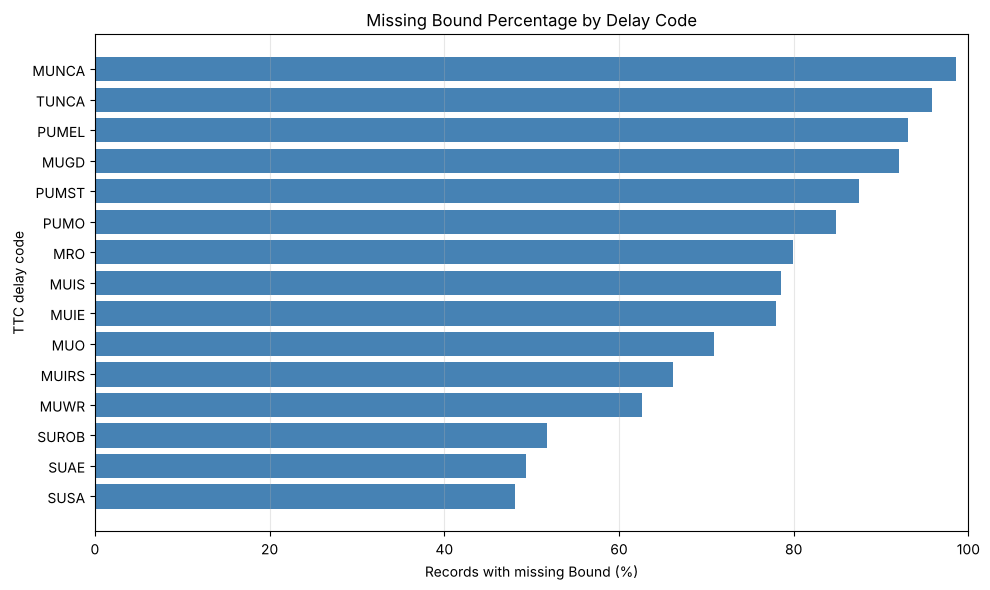

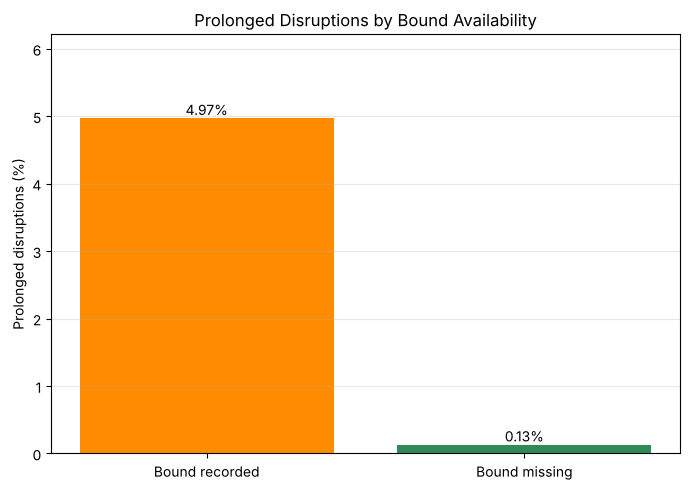

In [7]:
import matplotlib.pyplot as plt

# Plot missing-Bound rates for the most common, high-missingness codes.
plot_data = code_bound_summary.head(15).sort_values("Missing_Bound_Rate")
plt.figure(figsize=(10, 6))
plt.barh(plot_data.index, plot_data["Missing_Bound_Rate"], color="steelblue")
plt.xlabel("Records with missing Bound (%)")
plt.ylabel("TTC delay code")
plt.title("Missing Bound Percentage by Delay Code")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Compare prolonged-disruption rates for missing and recorded directions.
rate_plot = bound_prolonged_rate["Prolonged disruption percentage"]
plt.figure(figsize=(7, 5))
bars = plt.bar(rate_plot.index, rate_plot.values, color=["darkorange", "seagreen"])
plt.ylabel("Prolonged disruptions (%)")
plt.title("Prolonged Disruptions by Bound Availability")
plt.ylim(0, max(rate_plot.max() * 1.25, 1))
plt.grid(axis="y", alpha=0.3)
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom"
    )
plt.tight_layout()
plt.show()

## Translating Delay Codes

The `Code` column stores TTC internal incident codes such as `SUDP` or `MUIS`. These are not readable on their own, so we load the official delay-code dictionary and attach a plain-language description to every record.

The dictionary workbook stores two tables side by side in the same sheet: subway (`SUB RMENU CODE`) codes on the left and Scarborough RT (`SRT RMENU CODE`) codes on the right. We read both blocks and stack them into a single lookup table.

Descriptions are used for interpretation only. The model will still use the code itself as a categorical feature, because the description carries no extra information beyond the code.

In [8]:
# The dictionary has no usable header row, so we read it without one.
codes_raw = pd.read_excel('ttc-subway-delay-codes.xlsx', header=None)

# Columns 2-3 hold the subway codes; columns 6-7 hold the Scarborough RT codes.
sub_codes = codes_raw.iloc[2:, [2, 3]].dropna()
srt_codes = codes_raw.iloc[2:, [6, 7]].dropna()
sub_codes.columns = ["Code", "Code_Description"]
srt_codes.columns = ["Code", "Code_Description"]

code_lookup = (
    pd.concat([sub_codes, srt_codes], ignore_index=True)
    .assign(Code=lambda d: d["Code"].str.strip())
    .drop_duplicates(subset="Code")
    .reset_index(drop=True)
)

print(f"Delay codes in dictionary: {len(code_lookup)}")

# Check how many records in our data can be matched to a description.
matched = df["Code"].isin(set(code_lookup["Code"]))
print(f"Records matched to a description: {matched.mean() * 100:.2f}%")
print(f"Codes with no dictionary entry: {df.loc[~matched, 'Code'].nunique()}")
display(df.loc[~matched, "Code"].value_counts().head(10).to_frame("Records"))

Delay codes in dictionary: 200
Records matched to a description: 97.07%
Codes with no dictionary entry: 8


,Records
Code,
MUNCA,1226
TUNCA,168
PUEO,32
TRNCA,9
MUPF,7
PUEME,2
XXXXX,2
PUEWZ,2


About 97% of records match a dictionary entry. The unmatched codes are dominated by `MUNCA` and `TUNCA`, which follow the TTC naming pattern for "No Code Available" entries. These are administrative records rather than described incident types, so we label them explicitly instead of leaving the description blank.

In [9]:
# Attach descriptions to both subsets. This is a static lookup, not a value
# learned from the data, so applying it to the test set causes no leakage.
def add_code_description(data):
    out = data.merge(code_lookup, on="Code", how="left")
    out["Code_Description"] = out["Code_Description"].fillna("No code available / undocumented")
    return out

train_df = add_code_description(train_df)
test_df = add_code_description(test_df)

display(
    train_df[["Code", "Code_Description", "Min Delay"]]
    .drop_duplicates(subset="Code")
    .head(8)
)

,Code,Code_Description,Min Delay
0,EUME,RC&S Maintenance Error - (Human),3
1,SUDP,Disorderly Patron,0
3,SUO,Passenger Other,0
4,MUDD,Door Problems - Debris Related,0
6,MUIS,Injured or ill Customer (In Station) - Transpo...,0
7,MUIRS,Injured or ill Customer (In Station) - Medical...,0
8,SUAE,Assault / Employee Involved,0
9,MUO,Miscellaneous Other,0


## Row-Level Cleaning

The earlier audit identified missing values. Here we address the remaining messiness the milestone asks about: duplicate records, inconsistent formats, and invalid ranges.

Every step below is deterministic. It uses a fixed rule or an external dictionary rather than a statistic estimated from the data, so applying it to the training and test sets separately does not leak information between them. Steps that *do* learn from data, such as median imputation or category encoding, are deliberately left for the modeling phase and are listed in the preprocessing summary at the end.

**Inconsistent formats.** The `Line` column contains 26 distinct values, but the TTC operates only four rapid-transit lines in this period. The extra values are spelling variants of the same lines (`YU/BD`, `YU / BD`, `YUS/BD`, `BD/YU`), descriptive text (`BLOOR DANFORTH`, `LINE 1`), and clear data-entry errors (`999`, `77 SWANSEA`, which is a streetcar route). We map the recognisable variants onto canonical line names and group the rest as `Other/Unknown` rather than deleting the rows, because the other fields in those records are still valid.

**Invalid ranges.** `Min Gap` is the gap in service created by the incident and `Min Delay` is the delay to the train. A gap shorter than the delay it caused is not operationally meaningful, so those records are flagged as suspect.

**Disguised missing values.** `Vehicle` uses `0` where no vehicle number was recorded. Stored as a number, `0` would be read as a real vehicle identifier, so we convert it to a proper missing value.

**Duplicates.** The 23 exact duplicate rows share the same date, minute, station, code, and delay. Two identical incidents logged in the same minute at the same station are far more likely to be a double-entry than two genuine events, so we remove the repeats and keep the first occurrence.

Because the split happened before this step, some duplicate pairs were separated into different subsets, so fewer than 23 rows are removed in total. The effect is negligible at this volume, and de-duplicating each subset independently keeps the two sets strictly separate.

In [10]:
# Canonical names for the four rapid-transit lines in this period.
LINE_MAP = {
    "YU": "YU", "YUS": "YU", "LINE 1": "YU",
    "YONGE UNIVERSITY": "YU", "YONGE-UNIVERSITY": "YU", "YU LINE 1": "YU",
    "BD": "BD", "LINE 2": "BD", "BD LINE 2": "BD",
    "BLOOR DANFORTH": "BD", "BLOOR-DANFORTH": "BD",
    "SHP": "SHP", "SHEP": "SHP", "LINE 4": "SHP", "SHEPPARD": "SHP",
    "SRT": "SRT", "LINE 3": "SRT", "SCARBOROUGH RT": "SRT",
}

# Variants that mean "an incident affecting more than one line".
MULTI_LINE_TOKENS = ["YU/BD", "YU / BD", "YU/ BD", "YUS/BD", "BD/YU", "YU & BD", "YU-BD"]


def clean_line(value):
    if pd.isna(value):
        return "Unknown"
    text = str(value).strip().upper()
    if text in MULTI_LINE_TOKENS or ("YU" in text and "BD" in text):
        return "Multiple lines"
    return LINE_MAP.get(text, "Other")


def clean_records(data):
    out = data.copy()

    # 1. Standardise the line names.
    out["Line_Clean"] = out["Line"].apply(clean_line)

    # 2. Station names are stored in upper case and truncated at 22 characters
    #    by the source system. We strip whitespace and collapse the repeated
    #    spaces so that the same station is not counted twice.
    out["Station_Clean"] = (
        out["Station"].str.upper().str.strip().str.replace(r"\s+", " ", regex=True)
    )

    # 3. Vehicle 0 is a placeholder, not a real vehicle number.
    out["Vehicle"] = out["Vehicle"].replace(0, np.nan)

    # 4. Flag records where the service gap is shorter than the delay.
    out["Invalid_Gap"] = out["Min Gap"] < out["Min Delay"]

    # 5. Drop exact duplicate reports, keeping the first occurrence.
    before = len(out)
    out = out.drop_duplicates(
        subset=["Date", "Time", "Station", "Code", "Min Delay", "Min Gap", "Line"],
        keep="first"
    )
    print(f"Duplicate reports removed: {before - len(out)}")

    return out.reset_index(drop=True)


print("Training set:")
train_df = clean_records(train_df)
print("Test set:")
test_df = clean_records(test_df)

print(f"\nRows after cleaning - training: {len(train_df):,}, test: {len(test_df):,}")
print(f"Line categories before cleaning: {df['Line'].nunique()}")
print(f"Line categories after cleaning:  {train_df['Line_Clean'].nunique()}")
display(train_df["Line_Clean"].value_counts().to_frame("Records"))
print(f"Records with Min Gap < Min Delay: {train_df['Invalid_Gap'].sum()}")
print(f"Missing Vehicle numbers after recoding 0: {train_df['Vehicle'].isna().sum():,}")

Training set:
Duplicate reports removed: 18
Test set:


Duplicate reports removed: 1

Rows after cleaning - training: 39,514, test: 9,883
Line categories before cleaning: 26
Line categories after cleaning:  7


,Records
Line_Clean,
YU,20685
BD,16305
SHP,1293
SRT,587
Multiple lines,568
Unknown,69
Other,7


Records with Min Gap < Min Delay: 531
Missing Vehicle numbers after recoding 0: 16,975


### Cleaning decisions

| Issue found | Decision | Reason |
|---|---|---|
| 26 `Line` values for 4 real lines | Map variants to canonical names, group unrecognisable entries as `Other` | Keeps the rows usable without inventing a line |
| Exact duplicate reports | Remove, keep first occurrence | Same incident logged twice in the same minute |
| `Vehicle` stored as `0` | Convert to a missing value | `0` is a placeholder, not a vehicle number |
| `Min Gap` shorter than `Min Delay` | Flag, do not delete | Small number of records; a flag lets the modeling phase decide |
| Missing `Bound` (36.5%) | Keep as missing for now, label `Unknown` at modeling time | Shown earlier to be tied to incident type, not random |
| Missing `Line` (0.19%) | Falls into `Unknown` after cleaning | Too rare to affect results |

From this point onward the analysis uses `train_df` only. The test set is cleaned the same way but is not examined, so that no decision in this milestone is influenced by data the model will later be evaluated on.

## 4. Descriptive Statistics

Descriptive statistics summarise what the data looks like before any model is built. For the numerical columns we look at central tendency (mean, median), spread (standard deviation, quartiles), and distribution shape (skewness, kurtosis). For the categorical columns we use frequency counts to see which categories dominate and whether any class is too rare to learn from.

We also derive the temporal features here. `Time` is stored as text, so we convert it into an hour of day, which is the form the analysis and the later model will actually use.

In [11]:
# Derive the temporal features from the raw Date and Time columns.
def add_time_features(data):
    out = data.copy()
    out["Hour"] = pd.to_datetime(out["Time"], format="%H:%M").dt.hour
    # TTC peak periods: roughly 06:00-09:00 and 15:00-19:00 on weekdays.
    out["Is_Rush_Hour"] = (
        out["Hour"].between(6, 9) | out["Hour"].between(15, 19)
    ) & (out["Is_Weekend"] == 0)
    out["Is_Rush_Hour"] = out["Is_Rush_Hour"].astype(int)
    return out


train_df = add_time_features(train_df)
test_df = add_time_features(test_df)

# Summary statistics for the numerical columns.
numeric_cols = ["Min Delay", "Min Gap", "Hour"]
numeric_summary = train_df[numeric_cols].describe().T
numeric_summary["skewness"] = train_df[numeric_cols].skew()
numeric_summary["kurtosis"] = train_df[numeric_cols].kurtosis()
numeric_summary["zeros (%)"] = (train_df[numeric_cols] == 0).mean() * 100

display(numeric_summary.round(2))

# The percentiles matter more than the mean for a heavily skewed variable.
print("Min Delay percentiles (minutes):")
display(
    train_df["Min Delay"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.999, 1.00])
    .round(1)
    .to_frame("Minutes")
)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,zeros (%)
Min Delay,39514.0,2.89,10.09,0.0,0.0,0.0,4.0,716.0,28.84,1474.30,64.42
Min Gap,39514.0,4.24,10.95,0.0,0.0,0.0,8.0,719.0,22.99,1081.52,65.75
Hour,39514.0,13.09,6.63,0.0,8.0,14.0,19.0,23.0,-0.33,-0.90,3.83


Min Delay percentiles (minutes):


,Minutes
0.500,0.0
0.750,4.0
0.900,7.0
0.950,12.0
0.990,29.0
0.999,112.0
1.000,716.0


In [12]:
# Frequency counts for the categorical features.
categorical_cols = ["Line_Clean", "Bound", "Day", "Code"]

for column in categorical_cols:
    counts = train_df[column].value_counts(dropna=False)
    share = (counts / len(train_df) * 100).round(2)
    summary = pd.DataFrame({"Records": counts, "Share (%)": share})
    print(f"--- {column} ({train_df[column].nunique()} distinct values) ---")
    display(summary.head(8))

# Station has very high cardinality, so we check concentration instead.
station_counts = train_df["Station_Clean"].value_counts()
print(f"Distinct stations: {len(station_counts)}")
print(f"Share of records in the 20 busiest stations: "
      f"{station_counts.head(20).sum() / len(train_df) * 100:.1f}%")
print(f"Stations with fewer than 30 records: {(station_counts < 30).sum()}")

--- Line_Clean (7 distinct values) ---


,Records,Share (%)
Line_Clean,,
YU,20685,52.35
BD,16305,41.26
SHP,1293,3.27
SRT,587,1.49
Multiple lines,568,1.44
Unknown,69,0.17
Other,7,0.02


--- Bound (5 distinct values) ---


,Records,Share (%)
Bound,,
NaN,14420,36.49
S,7015,17.75
N,6722,17.01
W,5700,14.43
E,5603,14.18
B,54,0.14


--- Day (7 distinct values) ---


,Records,Share (%)
Day,,
Wednesday,6119,15.49
Tuesday,6046,15.30
Thursday,6002,15.19
Friday,5831,14.76
Monday,5784,14.64
Saturday,5207,13.18
Sunday,4525,11.45


--- Code (178 distinct values) ---


,Records,Share (%)
Code,,
SUDP,5525,13.98
MUIS,4321,10.94
SUO,3922,9.93
MUPAA,2512,6.36
MUIRS,2290,5.80
PUOPO,1998,5.06
MUO,1648,4.17
PUMEL,1220,3.09


Distinct stations: 591
Share of records in the 20 busiest stations: 44.2%
Stations with fewer than 30 records: 503


### What the statistics show

**The delay variable is dominated by zeros.** Around 64% of all logged records have `Min Delay` equal to 0, and the median is 0 minutes. These are incidents that were reported but caused no measurable delay to service. The mean of roughly 2.9 minutes is therefore misleading on its own: among the records that did cause a delay, the median is about 5 minutes and the mean about 8 minutes. Any model trained on this data has to deal with the fact that most rows describe non-events.

**Both delay variables are extremely right-skewed.** A skewness far above zero and a very high kurtosis confirm a long thin tail: most incidents are short and a small number run for hours. This is expected for disruption data and is exactly the pattern the business problem cares about, since the rare long incidents are the ones that justify a bus bridge.

**Categorical balance varies widely.** `Line_Clean` is dominated by the two main lines (YU and BD together account for over 90% of records), which matches real ridership. `Code` has roughly 180 distinct values with a long tail, and `Station_Clean` has nearly 600, many with very few records. Both will need grouping of rare categories before encoding, otherwise the model will see categories that appear only once or twice.

**`Bound` is missing for about a third of records**, as established in the earlier section, and `Hour` shows activity across the full day with the quiet period between 03:00 and 05:00.

## 5. Outliers and Data-Quality Checks

An outlier is a value far from the rest of the distribution. The standard approach is the interquartile range (IQR) rule, which treats any value beyond 1.5 times the IQR from the quartiles as an outlier.

This rule behaves oddly on our data. Because more than half of the records are exactly 0, both the first and third quartiles sit very low, so the IQR is small and the rule flags a large share of ordinary delays as outliers. We therefore report the IQR result, but judge the extreme values by operational relevance rather than by the rule alone.

In [13]:
import matplotlib.pyplot as plt

# Standard IQR rule on the delay variable.
q1, q3 = train_df["Min Delay"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outliers = train_df["Min Delay"] > upper_fence

print(f"Q1 = {q1:.1f} min, Q3 = {q3:.1f} min, IQR = {iqr:.1f} min")
print(f"IQR upper fence: {upper_fence:.1f} minutes")
print(f"Records above the fence: {outliers.sum():,} ({outliers.mean() * 100:.2f}%)")
print(f"Longest recorded delay: {train_df['Min Delay'].max():,} minutes "
      f"({train_df['Min Delay'].max() / 60:.1f} hours)")

# The most extreme records, checked against their incident descriptions.
print("\nTen longest delays in the training set:")
display(
    train_df.nlargest(10, "Min Delay")[
        ["Date", "Time", "Station_Clean", "Line_Clean", "Code",
         "Code_Description", "Min Delay", "Min Gap"]
    ]
)

Q1 = 0.0 min, Q3 = 4.0 min, IQR = 4.0 min
IQR upper fence: 10.0 minutes
Records above the fence: 2,314 (5.86%)
Longest recorded delay: 716 minutes (11.9 hours)

Ten longest delays in the training set:


,Date,Time,Station_Clean,Line_Clean,Code,Code_Description,Min Delay,Min Gap
8359,2024-05-13,07:01,BROADVIEW AND ST GEORG,BD,EUCD,Consequential Delay (2nd Delay Same Fault),716,719
3977,2024-04-25,15:36,ISLINGTON TO KIPLING,BD,MUPLB,Fire/Smoke Plan B - Source TTC,640,645
149,2024-03-01,06:08,MUSEUM STATION,YU,PUTSM,Track Switch Failure - Track Related Problem,491,496
8798,2023-07-24,18:43,ELLESMERE STATION,SRT,ERCO,Couplers,423,428
30296,2023-04-16,08:49,LAWRENCE EAST STATION,SRT,PRSL,Loop Related Failures,420,426
7638,2023-04-25,09:57,BLOOR STATION,YU,MUPLB,Fire/Smoke Plan B - Source TTC,360,363
11622,2024-07-16,16:00,OLD MILL STATION,BD,MUWEA,Weather Reports / Related Delays,340,344
7654,2023-02-03,17:54,MCCOWAN STATION,SRT,PRS,VCC/RCIU/CCR,309,316
32780,2023-06-18,21:14,MCCOWAN STATION,SRT,ERBO,Body,268,275
12735,2024-04-26,12:06,SHERBOURNE STATION,BD,SUPOL,Held By Polce - Non-TTC Related,217,222


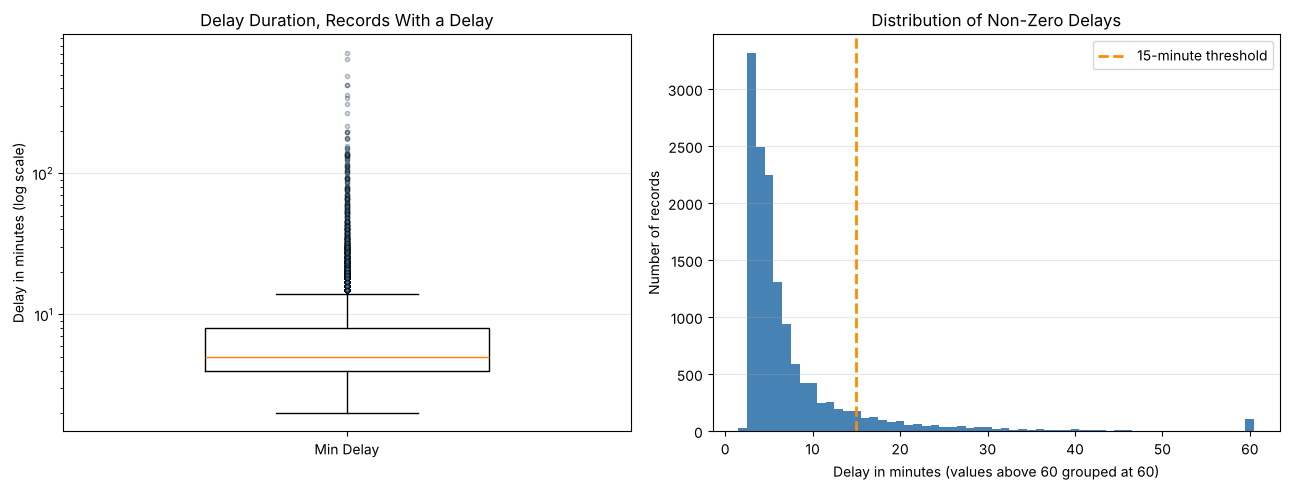

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: boxplot on a log scale so the bulk and the tail are both visible.
axes[0].boxplot(
    train_df.loc[train_df["Min Delay"] > 0, "Min Delay"],
    widths=0.5,
    flierprops=dict(marker="o", markersize=3, alpha=0.25, markerfacecolor="steelblue")
)
axes[0].set_yscale("log")
axes[0].set_ylabel("Delay in minutes (log scale)")
axes[0].set_title("Delay Duration, Records With a Delay")
axes[0].set_xticklabels(["Min Delay"])
axes[0].grid(axis="y", alpha=0.3)

# Right: histogram of the delays that matter operationally.
capped = train_df.loc[train_df["Min Delay"] > 0, "Min Delay"].clip(upper=60)
# Delays are whole minutes, so one bin per minute avoids empty gaps.
axes[1].hist(capped, bins=np.arange(1.5, 61.5, 1), color="steelblue")
axes[1].axvline(15, color="darkorange", linestyle="--", linewidth=2,
                label="15-minute threshold")
axes[1].set_xlabel("Delay in minutes (values above 60 grouped at 60)")
axes[1].set_ylabel("Number of records")
axes[1].set_title("Distribution of Non-Zero Delays")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Outlier decision

The ten longest delays are not data errors. Each maps to a documented incident type: equipment and infrastructure failures (a track switch, couplers, train body and control systems), fire/smoke evacuations, severe weather, a police hold, and a consequential delay from an earlier fault. These are the events a bus bridge exists to handle, so removing them would delete the signal the project is trying to learn. Four of the ten occurred on the SRT, consistent with that line's higher prolonged rate shown in the next section.

Our decisions are therefore:

- **Classification target: retain all outliers unchanged.** The target only records whether a delay crossed the threshold, so the exact length of an extreme delay does not distort it. A seven-hour shutdown and a twenty-minute one are both simply `1`.
- **Regression target: retain the values, and cap only if a model requires it.** The 716-minute maximum is genuine but would dominate a squared-error loss. If a linear model is used later, we will either cap at the 99.5th percentile or predict the log of the delay. This is a modeling choice, so it is recorded in the preprocessing plan rather than applied to the data now.
- **The `Invalid_Gap` records are kept and flagged**, since there are few of them and the remaining fields are valid.

## 6. Target Variable Exploration

This project has two targets, defined in Milestone 2:

- **Classification:** `Prolonged_Disruption`, equal to 1 when the delay exceeds the operational threshold.
- **Regression:** `Min Delay`, the delay duration in minutes.

We examine the class balance of the first and the range, skew, and variance of the second, then check which input features carry signal about them.

In [15]:
# Class balance of the classification target.
class_counts = train_df["Prolonged_Disruption"].value_counts().sort_index()
class_share = (class_counts / len(train_df) * 100).round(2)
display(
    pd.DataFrame({
        "Records": class_counts,
        "Share (%)": class_share
    }).rename(index={0: "Short (<= 15 min)", 1: "Prolonged (> 15 min)"})
)

minority_share = train_df["Prolonged_Disruption"].mean()
print(f"Minority class share: {minority_share * 100:.2f}%")
print(f"Imbalance ratio: 1 prolonged incident for every "
      f"{(1 - minority_share) / minority_share:.0f} short ones")

,Records,Share (%)
Prolonged_Disruption,,
Short (<= 15 min),38250,96.8
Prolonged (> 15 min),1264,3.2


Minority class share: 3.20%
Imbalance ratio: 1 prolonged incident for every 30 short ones


### The class imbalance is severe

Only about 3% of records are prolonged disruptions. This confirms the concern raised in the Milestone 2 success criteria: a model that always predicts "short" would be roughly 97% accurate while being completely useless, because it would never trigger a bus bridge. Accuracy must not be the headline metric, and the modeling phase will need class weights or resampling.

### Checking the threshold

Milestone 2 stated that the threshold should be anchored to the time needed to organise and deploy a bus bridge, with the exact value confirmed against the historical distribution. Now that we can see the distribution, we test how sensitive the target is to that choice.

In [16]:
# How does the positive-class share change with the threshold?
thresholds = [5, 10, 15, 20, 30, 45, 60]
sensitivity = pd.DataFrame({
    "Threshold (min)": thresholds,
    "Positive records": [(train_df["Min Delay"] > t).sum() for t in thresholds],
    "Positive share (%)": [
        round((train_df["Min Delay"] > t).mean() * 100, 2) for t in thresholds
    ],
})
display(sensitivity)

,Threshold (min),Positive records,Positive share (%)
0,5,5983,15.14
1,10,2314,5.86
2,15,1264,3.20
3,20,762,1.93
4,30,336,0.85
5,45,153,0.39
6,60,102,0.26


A 15-minute threshold keeps about 3% of records in the positive class. Lowering it to 10 minutes roughly doubles the positive class, which would make the model easier to train but would label incidents as "prolonged" that clear before shuttles could realistically arrive. Raising it to 30 minutes leaves barely 1% of records, too few examples to learn from reliably.

The 15-minute value is defensible on both counts: it is long enough that a bus bridge is still useful when the prediction is correct, and it leaves enough positive examples to train on. We keep it, and record the alternatives above so the choice can be revisited during modeling.

### A scope question for the modeling phase

The 3% figure is computed over every logged record, including the roughly 64% that never delayed a train at all. Many of those are reports that would never reach a bus-bridge decision, such as graffiti, stairway incidents, or administrative entries. We check how the class balance changes if the model is restricted to incidents that caused at least some delay.

In [17]:
# Class balance if only incidents with a non-zero delay are modeled.
delayed_only = train_df[train_df["Min Delay"] > 0]
print(f"All records:              {len(train_df):,} rows, "
      f"{train_df['Prolonged_Disruption'].mean() * 100:.2f}% prolonged")
print(f"Records with a delay > 0: {len(delayed_only):,} rows, "
      f"{delayed_only['Prolonged_Disruption'].mean() * 100:.2f}% prolonged")

All records:              39,514 rows, 3.20% prolonged
Records with a delay > 0: 14,060 rows, 8.99% prolonged


Restricting to delayed incidents roughly triples the positive share, to about 9%, which makes the classification problem considerably easier. It also changes the question being answered: the model would then predict whether an incident that *has already started delaying trains* will become prolonged, rather than whether any newly logged report will.

This is a scope decision for the group rather than an analytical one, because it changes the problem defined in Milestone 2. We keep the full dataset as the default in this milestone and flag the restricted version as the main alternative to compare during modeling.

In [18]:
# Distribution characteristics of the regression target.
delay = train_df["Min Delay"]
nonzero_delay = delay[delay > 0]

regression_summary = pd.DataFrame({
    "All records": [
        delay.min(), delay.max(), delay.mean(), delay.median(),
        delay.var(), delay.std(), delay.skew(), delay.kurtosis()
    ],
    "Records with a delay": [
        nonzero_delay.min(), nonzero_delay.max(), nonzero_delay.mean(),
        nonzero_delay.median(), nonzero_delay.var(), nonzero_delay.std(),
        nonzero_delay.skew(), nonzero_delay.kurtosis()
    ],
}, index=["min", "max", "mean", "median", "variance",
          "std deviation", "skewness", "kurtosis"])

display(regression_summary.round(2))

# A log transform is the usual remedy for this much skew.
log_skew = np.log1p(nonzero_delay).skew()
print(f"Skewness of non-zero delays: {nonzero_delay.skew():.2f}")
print(f"Skewness after a log(1 + x) transform: {log_skew:.2f}")

,All records,Records with a delay
min,0.00,2.00
max,716.00,716.00
mean,2.89,8.11
median,0.00,5.00
variance,101.73,243.55
std deviation,10.09,15.61
skewness,28.84,20.86
kurtosis,1474.30,693.04


Skewness of non-zero delays: 20.86
Skewness after a log(1 + x) transform: 1.73


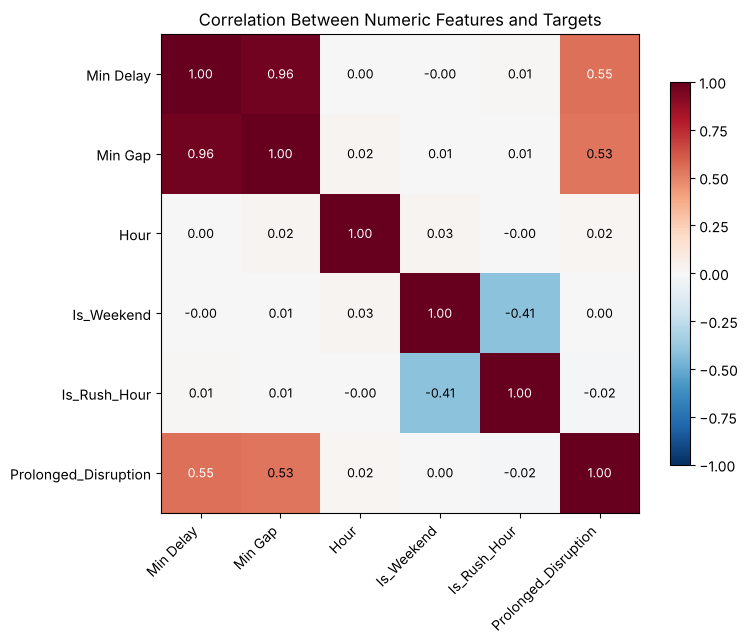

In [19]:
# Correlation between the numeric columns and the two targets.
correlation_cols = ["Min Delay", "Min Gap", "Hour", "Is_Weekend",
                    "Is_Rush_Hour", "Prolonged_Disruption"]
correlation_matrix = train_df[correlation_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(correlation_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_cols)))
ax.set_yticks(range(len(correlation_cols)))
ax.set_xticklabels(correlation_cols, rotation=45, ha="right")
ax.set_yticklabels(correlation_cols)
ax.set_title("Correlation Between Numeric Features and Targets")

for i in range(len(correlation_cols)):
    for j in range(len(correlation_cols)):
        value = correlation_matrix.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.55 else "black", fontsize=9)

fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

### A leakage problem in `Min Gap`

`Min Gap` correlates with `Min Delay` at about 0.96. That looks like the most valuable predictor in the dataset, and it is the kind of feature that would produce an impressively accurate model and a useless one.

As we read the dataset's column definition, `Min Gap` is the gap in service between trains caused by the incident. We have not found TTC documentation stating exactly when it is recorded, but by that definition it can only be known once the disruption has played out, the same moment the delay itself becomes known. The ten longest delays in the outlier section support this reading: in every case the gap sits just a few minutes above the delay. Milestone 2 states that predictions must use only the information a dispatcher has at the onset of an incident, so `Min Gap` would not be available when the decision has to be made. Including it would mean predicting the delay from a measurement of the delay.

**`Min Gap` must be excluded from the feature set for both targets.** It remains useful for data-quality checks, such as the `Invalid_Gap` flag, but not as an input.

The remaining numeric correlations are weak, which is expected: the real signal in this dataset is categorical, so we examine it by group instead.

In [20]:
# Which incident types are most likely to become prolonged?
code_risk = (
    train_df.groupby(["Code", "Code_Description"])
    .agg(
        Records=("Prolonged_Disruption", "size"),
        Prolonged_Rate=("Prolonged_Disruption", "mean"),
        Average_Delay=("Min Delay", "mean"),
    )
    .reset_index()
)

# Rates from very small groups are unstable, so we require a minimum count.
code_risk = code_risk[code_risk["Records"] >= 150].copy()
code_risk["Prolonged_Rate"] = (code_risk["Prolonged_Rate"] * 100).round(2)
code_risk["Average_Delay"] = code_risk["Average_Delay"].round(2)
code_risk = code_risk.sort_values("Prolonged_Rate", ascending=False)

print(f"Baseline prolonged rate across all records: {minority_share * 100:.2f}%")
print("\nIncident types most likely to become prolonged:")
display(code_risk.head(10).set_index("Code"))
print("Incident types least likely to become prolonged:")
display(code_risk.tail(5).set_index("Code"))

Baseline prolonged rate across all records: 3.20%

Incident types most likely to become prolonged:


,Code_Description,Records,Prolonged_Rate,Average_Delay
Code,,,,
MUI,Injured or ill Customer (On Train) - Transported,627,18.82,9.33
SUEAS,Emergency Alarm Station Activation,214,16.82,11.75
SUUT,Unauthorized at Track Level,1119,16.26,8.21
PUTWZ,Work Zone Problems - Track,170,12.94,8.71
MUIR,Injured or ill Customer (On Train) - Medical A...,1065,6.10,5.29
SUAP,Assault / Patron Involved,1007,5.36,2.67
SUO,Passenger Other,3922,4.61,2.21
SUDP,Disorderly Patron,5525,3.02,2.61
SUAE,Assault / Employee Involved,330,2.73,1.37


Incident types least likely to become prolonged:


,Code_Description,Records,Prolonged_Rate,Average_Delay
Code,,,,
PUMST,Station Stairway Incident,494,0.0,0.01
SUG,Graffiti / Scratchiti,436,0.0,2.30
TUNIP,Operator Not In Position,151,0.0,4.21
TUNOA,No Operator Immediately Available,152,0.0,3.64
TUSC,Operator Overspeeding,644,0.0,0.42


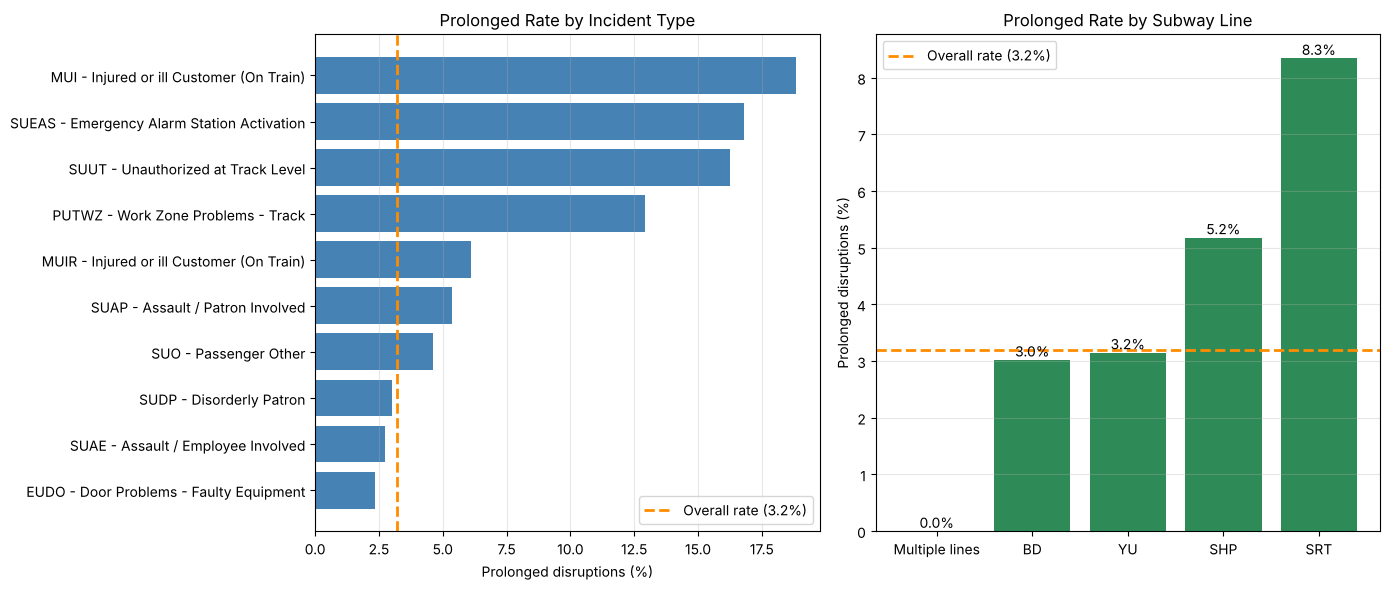

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: the incident codes with the highest prolonged rate.
top_codes = code_risk.head(10).sort_values("Prolonged_Rate")
labels = [
    f"{row.Code} - {row.Code_Description[:34]}"
    for row in top_codes.itertuples()
]
axes[0].barh(labels, top_codes["Prolonged_Rate"], color="steelblue")
axes[0].axvline(minority_share * 100, color="darkorange", linestyle="--",
                linewidth=2, label=f"Overall rate ({minority_share * 100:.1f}%)")
axes[0].set_xlabel("Prolonged disruptions (%)")
axes[0].set_title("Prolonged Rate by Incident Type")
axes[0].legend()
axes[0].grid(axis="x", alpha=0.3)

# Right: the prolonged rate by line.
line_risk = (
    train_df.groupby("Line_Clean")
    .agg(Records=("Prolonged_Disruption", "size"),
         Rate=("Prolonged_Disruption", "mean"))
)
line_risk = line_risk[line_risk["Records"] >= 100].sort_values("Rate")
bars = axes[1].bar(line_risk.index, line_risk["Rate"] * 100, color="seagreen")
axes[1].axhline(minority_share * 100, color="darkorange", linestyle="--",
                linewidth=2, label=f"Overall rate ({minority_share * 100:.1f}%)")
axes[1].set_ylabel("Prolonged disruptions (%)")
axes[1].set_title("Prolonged Rate by Subway Line")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                 f"{bar.get_height():.1f}%", ha="center", va="bottom")

plt.tight_layout()
plt.show()

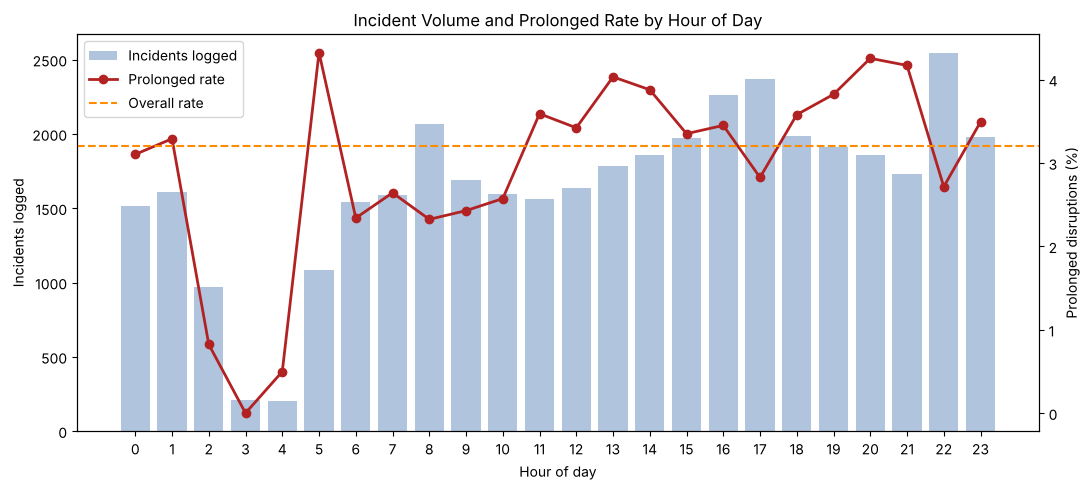

Prolonged rate by period:


,Records,Rate
Is_Rush_Hour,,
Off-peak,26092,3.40
Weekday rush hour,13422,2.82


In [22]:
# Does the time of day carry signal?
hourly = (
    train_df.groupby("Hour")
    .agg(Records=("Prolonged_Disruption", "size"),
         Rate=("Prolonged_Disruption", "mean"))
)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(hourly.index, hourly["Records"], color="lightsteelblue",
        label="Incidents logged")
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("Incidents logged")
ax1.set_xticks(range(0, 24))

ax2 = ax1.twinx()
ax2.plot(hourly.index, hourly["Rate"] * 100, color="firebrick",
         marker="o", linewidth=2, label="Prolonged rate")
ax2.axhline(minority_share * 100, color="darkorange", linestyle="--",
            linewidth=1.5, label="Overall rate")
ax2.set_ylabel("Prolonged disruptions (%)")

ax1.set_title("Incident Volume and Prolonged Rate by Hour of Day")
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
plt.tight_layout()
plt.show()

print("Prolonged rate by period:")
display(
    train_df.groupby("Is_Rush_Hour")["Prolonged_Disruption"]
    .agg(Records="size", Rate="mean")
    .assign(Rate=lambda d: (d["Rate"] * 100).round(2))
    .rename(index={0: "Off-peak", 1: "Weekday rush hour"})
)

### Ranking the features formally

The charts above compare features visually. To rank them on a common scale we use two association measures between each candidate feature and the classification target:

- **Mutual information** measures how much knowing a feature reduces uncertainty about the target. It is zero when the two are independent.
- **Cramér's V** measures the strength of association between two categorical variables on a 0-to-1 scale.

Both measures are inflated for high-cardinality features: a column with hundreds of rare categories will show some association with the target purely by chance. To correct for this, we also compute the mutual information against a randomly shuffled target, which estimates how much of the score is noise, and rank features by the difference.

In [23]:
from sklearn.metrics import mutual_info_score
from scipy.stats import chi2_contingency  # scipy is installed with scikit-learn

candidate_features = ["Code", "Bound", "Station_Clean", "Line_Clean", "Hour",
                      "Is_Rush_Hour", "Day", "Is_Weekend", "Month", "Season"]
target = train_df["Prolonged_Disruption"]
rng = np.random.default_rng(RANDOM_STATE)

ranking_rows = []
for feature in candidate_features:
    # Missing values are treated as their own category, matching the 'Unknown' plan.
    values = train_df[feature].fillna("Unknown").astype(str)

    mutual_info = mutual_info_score(values, target)
    shuffled_mi = np.mean([
        mutual_info_score(values, rng.permutation(target.values))
        for _ in range(20)
    ])

    table = pd.crosstab(values, target)
    chi2 = chi2_contingency(table)[0]
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

    ranking_rows.append({
        "Feature": feature,
        "Categories": values.nunique(),
        "Mutual information": mutual_info,
        "MI from chance": shuffled_mi,
        "MI above chance": mutual_info - shuffled_mi,
        "Cramér's V": cramers_v,
    })

feature_ranking = (
    pd.DataFrame(ranking_rows)
    .set_index("Feature")
    .sort_values("MI above chance", ascending=False)
)
display(feature_ranking.round(4))

,Categories,Mutual information,MI from chance,MI above chance,Cramér's V
Feature,,,,,
Code,178,0.0354,0.0019,0.0335,0.3748
Bound,6,0.0126,0.0001,0.0125,0.1328
Station_Clean,591,0.0070,0.0034,0.0036,0.1621
Line_Clean,7,0.0013,0.0001,0.0012,0.0563
Hour,24,0.0012,0.0003,0.0009,0.0441
Is_Rush_Hour,2,0.0001,0.0000,0.0001,0.0154
Season,4,0.0000,0.0000,0.0000,0.0086
Is_Weekend,2,0.0000,0.0000,-0.0000,0.0034
Day,7,0.0000,0.0001,-0.0000,0.0075


### Which variables are informative

**`Code` is the strongest predictor on every measure.** Its mutual information above chance is more than double that of any other feature, and its Cramér's V is the highest by a wide margin. The prolonged rate ranges from effectively 0% for incident types such as stairway incidents and speed-control events up to nearly 19% for injured customers requiring transport, a six-fold difference from the 3% baseline. `Code` is available the moment an incident is logged, so it satisfies the onset-availability constraint. One nuance: the codes behind the very longest delays (equipment failures, fire/smoke) are rare, while the codes with the highest prolonged *rate* are frequent passenger-related incidents. A model needs to learn both patterns.

**`Bound` ranks second, which we did not expect.** A direction of travel says little about severity on its own; the signal comes from *whether* `Bound` is recorded. The missing-direction analysis earlier showed that missingness is tied to particular incident types, and this ranking confirms that the missingness itself is informative. That strongly supports keeping missing values as an explicit `Unknown` category rather than imputing a direction. This assumes the direction is recorded when the incident is logged, which is the natural reading of the field.

**`Station_Clean` is informative but inflated.** Its raw mutual information looks reasonable, but about half of it is matched by the shuffled baseline, a direct sign of the cardinality problem. With nearly 600 categories and most holding only a handful of records, raw station identity would overfit. Rare stations need to be grouped before encoding.

**`Line_Clean` carries a weak signal.** The SRT and Sheppard lines show higher prolonged rates than the two main lines. The data does not tell us why, so we report the difference without assigning a cause. The `Multiple lines` group shows a 0% rate because it is not really a group of service incidents: all of its records have a delay of 0 minutes and almost all are coded "Miscellaneous Other" against a combined Yonge-University/Bloor-Danforth location, which points to administrative log entries.

**Time of day is weak.** Incident volume varies strongly across the day, but the prolonged *rate* stays within about one percentage point of the baseline for most hours. Weekday rush hours have a slightly *lower* prolonged rate than off-peak periods (about 2.8% versus 3.4%). The low-volume overnight hours produce unstable rates rather than real signal.

**Calendar features carry no measurable signal.** `Day`, `Is_Weekend`, `Month`, and `Season` all score at or below the shuffled baseline. They remain useful for stratifying the split, but there is no evidence that they help predict whether an incident becomes prolonged.

## 7. Preprocessing Summary and Readiness for Modeling

This section collects the EDA findings into the preprocessing plan for the modeling phase.

### Summary of findings

1. The combined 2023-2024 dataset holds roughly 49,000 incident records across 10 original columns, with no missing values except `Bound` (36.5%) and `Line` (0.19%).
2. About 64% of records have a delay of exactly 0 minutes. Most logged incidents never affect service.
3. The classification target is severely imbalanced: roughly 3% of records are prolonged disruptions at the 15-minute threshold.
4. Both delay variables are extremely right-skewed, with a maximum of 716 minutes. The extreme values are genuine incidents, not errors.
5. `Min Gap` correlates with `Min Delay` at 0.96 and, by its definition, is only known after the incident resolves. We treat it as leakage rather than a feature.
6. `Code` is the strongest available predictor on every measure, separating incident types from a 0% to a nearly 19% prolonged rate.
7. `Bound` is the second most informative feature, because its missingness is tied to incident type. Missing values should be kept as an explicit category.
8. Calendar features (`Day`, `Is_Weekend`, `Month`, `Season`) show no measurable association with the target.
9. `Line` and `Station` contain inconsistent formats and high cardinality that must be handled before encoding.
10. Restricting the model to incidents with a non-zero delay would raise the positive share from about 3% to about 9%. This is a scope decision left to the group.

### Feature decisions

In [24]:
feature_plan = pd.DataFrame([
    ("Code", "Categorical", "Keep", "Strongest predictor; known at incident onset"),
    ("Line_Clean", "Categorical", "Keep", "Cleaned to 4 lines plus Multiple/Unknown"),
    ("Station_Clean", "Categorical", "Keep, grouped", "Group stations below 30 records as 'Other'"),
    ("Bound", "Categorical", "Keep, missing as 'Unknown'", "2nd most informative; missingness tied to incident type"),
    ("Hour", "Numerical", "Keep", "Derived from Time; weak signal"),
    ("Is_Rush_Hour", "Binary", "Keep", "Weak signal; operational context for the threshold"),
    ("Day / Is_Weekend", "Categorical", "Low priority", "No signal above chance; drop if feature selection agrees"),
    ("Month / Season", "Categorical", "Low priority", "No signal above chance; drop if feature selection agrees"),
    ("Invalid_Gap", "Binary", "EXCLUDE (quality flag only)", "Computed from Min Gap and the target itself"),
    ("Min Gap", "Numerical", "EXCLUDE", "Leakage: by definition known only after the delay"),
    ("Vehicle", "Identifier", "EXCLUDE", "Vehicle number is a label; 43% are placeholders"),
    ("Date / Time", "Temporal", "EXCLUDE (raw)", "Replaced by the derived Hour, Day, Month features"),
    ("Min Delay", "Target", "Regression target", "Also the source of the classification target"),
    ("Prolonged_Disruption", "Target", "Classification target", "1 when Min Delay > 15 minutes"),
], columns=["Feature", "Type", "Decision", "Reason"])

display(feature_plan.set_index("Feature"))

# Calendar features are kept as low-priority candidates; Invalid_Gap is excluded
# because it is computed from Min Gap and from the target itself.
modelling_features = [
    "Code", "Bound", "Station_Clean", "Line_Clean",
    "Hour", "Is_Rush_Hour", "Is_Weekend", "Day", "Month", "Season"
]
print(f"Candidate features for modeling: {len(modelling_features)}")
print(f"Training rows available: {len(train_df):,}")
print(f"Test rows held out:      {len(test_df):,}")

,Type,Decision,Reason
Feature,,,
Code,Categorical,Keep,Strongest predictor; known at incident onset
Line_Clean,Categorical,Keep,Cleaned to 4 lines plus Multiple/Unknown
Station_Clean,Categorical,"Keep, grouped",Group stations below 30 records as 'Other'
Bound,Categorical,"Keep, missing as 'Unknown'",2nd most informative; missingness tied to inci...
Hour,Numerical,Keep,Derived from Time; weak signal
Is_Rush_Hour,Binary,Keep,Weak signal; operational context for the thres...
Day / Is_Weekend,Categorical,Low priority,No signal above chance; drop if feature select...
Month / Season,Categorical,Low priority,No signal above chance; drop if feature select...
Invalid_Gap,Binary,EXCLUDE (quality flag only),Computed from Min Gap and the target itself


Candidate features for modeling: 10
Training rows available: 39,514
Test rows held out:      9,883


### Preprocessing steps for the modeling phase

The steps below are **not applied here**. Each one learns a value from the data (a category list, a frequency, a fitted encoder), so each must be fitted on the training set only and then applied unchanged to the test set. Carrying them out inside a scikit-learn `Pipeline` in the next milestone is the cleanest way to guarantee that.

1. **Impute `Bound`** with the literal category `Unknown` rather than a guessed direction, since the earlier analysis showed the missingness is tied to incident type.
2. **Group rare categories.** Stations with fewer than 30 training records, and delay codes below a similar threshold, collapse into an `Other` category. The cut-off is counted on the training set only.
3. **Encode the categorical features.** One-hot encoding for the low-cardinality columns (`Line_Clean`, `Bound`, `Day`, `Season`); target or frequency encoding for `Code` and `Station_Clean`, fitted on training folds only to avoid leaking the target.
4. **Address the class imbalance** with class weights, or with resampling applied inside the cross-validation folds rather than before splitting.
5. **Scale the numerical features** only for models that need it, such as logistic regression. Tree-based models do not.
6. **For the regression target**, either cap at the 99.5th percentile or model `log(1 + Min Delay)`, and report the error in minutes after transforming back.
7. **Compare two scopes**: the full dataset (the default, matching Milestone 2) and incidents with a non-zero delay only (about 9% positive). The group should agree on which one answers the business question before final evaluation.

### Readiness

The dataset is ready for modeling. The target is defined and validated against the historical distribution, the input features are categorised with a documented decision for each, the leakage risk in `Min Gap` has been identified and removed, and the test set has been held out and left unexamined. The main challenge carried into the next phase is the 3% positive class, which is why the Milestone 2 success criteria are built on recall, precision, and AUC rather than accuracy.

In [25]:
# Final check that the two subsets are consistent and ready to hand over.
summary = pd.DataFrame({
    "Training set": [
        len(train_df),
        train_df["Prolonged_Disruption"].sum(),
        round(train_df["Prolonged_Disruption"].mean() * 100, 2),
        round(train_df["Min Delay"].mean(), 2),
    ],
    "Test set": [
        len(test_df),
        test_df["Prolonged_Disruption"].sum(),
        round(test_df["Prolonged_Disruption"].mean() * 100, 2),
        round(test_df["Min Delay"].mean(), 2),
    ],
}, index=["Records", "Prolonged disruptions",
          "Prolonged share (%)", "Mean delay (min)"])

display(summary)
print("Stratification held: the prolonged share is comparable in both subsets.")
print(f"Columns available for modeling: {len(modelling_features)} features + 2 targets")

,Training set,Test set
Records,39514.00,9883.00
Prolonged disruptions,1264.00,316.00
Prolonged share (%),3.20,3.20
Mean delay (min),2.89,2.87


Stratification held: the prolonged share is comparable in both subsets.
Columns available for modeling: 10 features + 2 targets
